# Vežbe broj 05: jednačina stanja u jednom realističnom modelu zvezdane atmosfere

## Zadaci:

1) Učitati model FALC koji je dat u ovom repozitorijumu i iz njega proceniti ukupnu koncentraciju čestica (preko pritiska i temperature)

2) Rešiti jednačinu stanja za čist vodonik gde razmatramo neutralan vodonik, protone i elektrone. Prodiskutovati. 

3) Uporediti koncentraciju elektrona koju smo dobili sa koncentracijom elektrona koji su dati u modelu

4) Proceniti koncentraciju H-

5) Uporediti koncentraciju H- sa koncentracijama vodonika na prva tri nivoa. Prodiskutovati. 

6) 

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
atm = np.loadtxt('falc_71.dat',unpack=True, skiprows=1)
atm.shape

(12, 71)

In [3]:
# Trebaju nam samo prvih 5 kolona i one oznacavaju: 
# 0 - log opticka dubina u kontinuumu (najverovatnije na lambda = 500 nm)
# 1 - visina u odnosu na log tau = 0 (u cm )
# 2 - temperatura (u K)
# 3 - pritisak u dyn/cm^2 
# 4 - elektronski pritisak u dyn/cm^2

In [17]:
logtau, z, T, pg, pe = atm[:5]
z = z/1E5
# ostavicemo pritisak ovako pa cemo koncentraciju prebaciti u SI

### Zadatak 0 : Isplotujte razlicite zavisnosti od visine i opticke dubine da se upoznate malo bolje sa modelom.

Text(0, 0.5, 'T [K]')

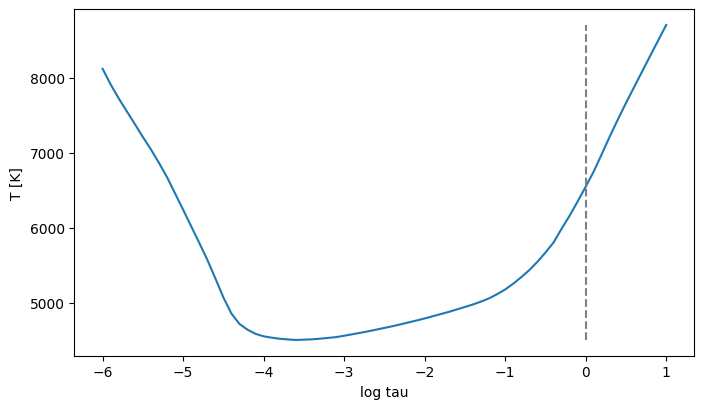

In [7]:
# Prvo T(tau)
plt.figure(figsize=[8,4.5])
plt.plot(logtau, T)
plt.vlines(0, ymin=min(T), ymax=max(T), linestyles='dashed', colors='gray')
plt.xlabel("log tau")
plt.ylabel("T [K]")

Text(0.5, 1.0, 'Temperatura u zavisnosti od visine')

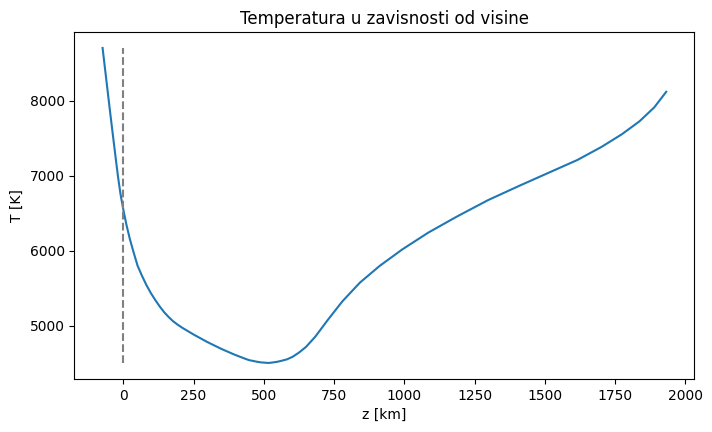

In [18]:
# Isto to u zavisnosti od visine:
plt.figure(figsize=[8,4.5])
plt.plot(z , T)
plt.vlines(0, ymin=min(T), ymax=max(T), linestyles='dashed', colors='gray')
plt.xlabel("z [km]")
plt.ylabel("T [K]")
plt.title("Temperatura u zavisnosti od visine")

Text(0.5, 1.0, 'Pritisak gasa u zavisnosti od visine')

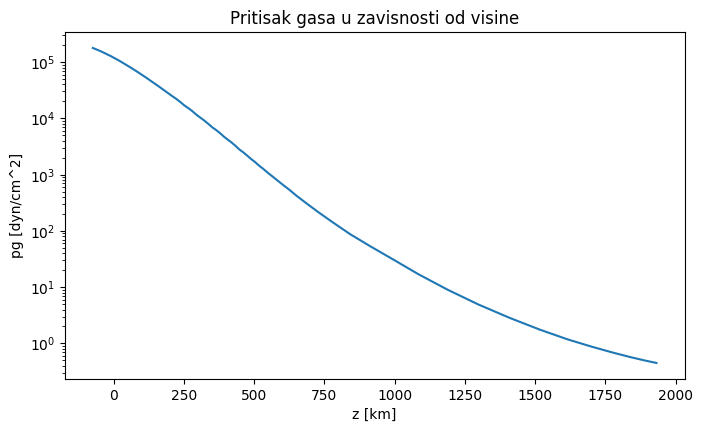

In [19]:
# Isto to za pritisak gasa: 
plt.figure(figsize=[8,4.5])
plt.semilogy(z, pg)
plt.xlabel("z [km]")
plt.ylabel("pg [dyn/cm^2]")
plt.title("Pritisak gasa u zavisnosti od visine")

### 1) Učitati model FALC koji je dat u ovom repozitorijumu i iz njega proceniti ukupnu koncentraciju čestica (preko pritiska i temperature)

In [24]:
# IMportujemo neke konstante
from scipy.constants import k, h, c, N_A, sigma, pi, m_e

In [20]:
# p = nkT 
# n = p / (k * T)
n = pg * 0.1 / (k * T) # Dobijamo u m^{-3}

Text(0.5, 1.0, 'Gustina broja čestica u zavisnosti od visine')

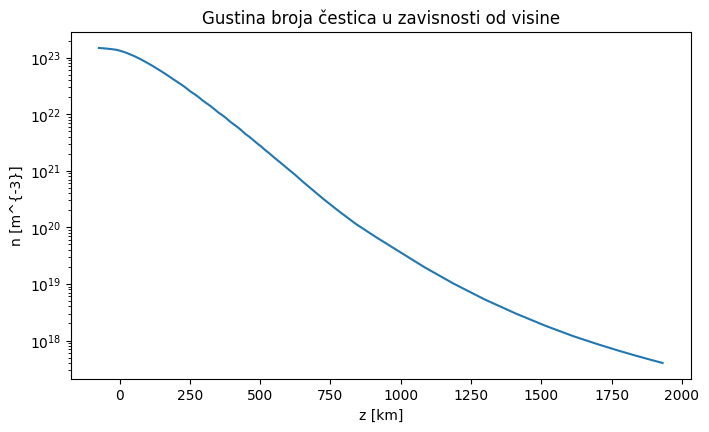

In [ ]:
plt.figure(figsize=[8,4.5])
plt.semilogy(z, n)
plt.xlabel("z [km]")
plt.ylabel("n [m^{-3}]")
plt.title("Gustina čestica u zavisnosti od visine")

### 2) Rešiti jednačinu stanja za čist vodonik gde razmatramo neutralan vodonik, protone i elektrone. Prodiskutovati. 

In [26]:
# Prvi korak je da iskoristimo sta smo radili na casu da na osnovu sahine jednacine za vodonik i protone resimo sistem 
# 3 nepoznate i 3 jednacine (nelinearan) i da dobijemo nH, np, ne

# Prvo definisimo clan fT u zavisnosti od T (to je clan koji sledi i Sahine jednacine)

def saha_kolicnik(T):
    gH = 2.0
    gp = 1.0
    deltaE = 13.6 * 1.6E-19 # J
    
    return (2.0 * pi * m_e * k * T / h**2.0) ** 1.5 * 2.0 * gp / gH * np.exp(-deltaE/k/T)

def nadji_ne_simple(n, T):
    
    # Ova funkcija vraca koncentraciju elektrona za datu ukupnu koncetnraciju cestica i temperaturu
    # pretpostavke koje smo uveli je da imamo samo neutralan i jednom jonizovan vodonik, i elektrone
    # onda je resenje relativno jednostavno, samo jedna kvadratna jednacina
    
    fT = saha_kolicnik(T)
    
    return -fT + (fT**2.0 + n*fT)**0.5

In [27]:
# Hajde da se pomolimo i da odmah ovo primenimo na ceo niz: 

ne_simple = nadji_ne_simple(n ,T)

Text(0.5, 1.0, 'Gustina čestica vs gustina elektrona u zavisnosti od visine')

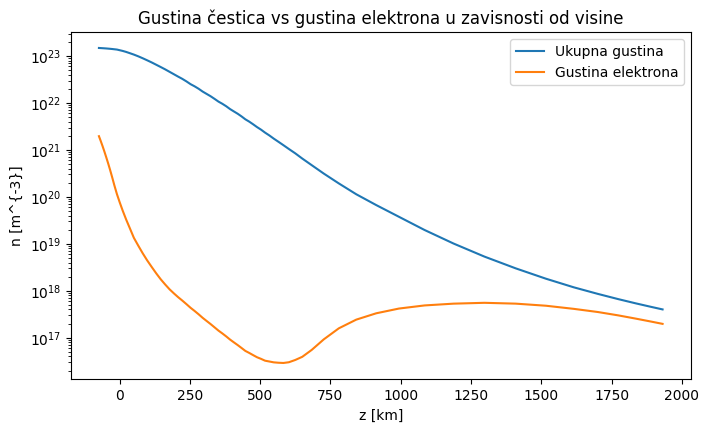

In [30]:
# Hajde da isplotujemo ovaj ne koji smo dobili i ukupan n koji imamo
plt.figure(figsize=[8,4.5])
plt.semilogy(z, n)
plt.semilogy(z, ne_simple)
plt.legend(["Ukupna gustina", "Gustina elektrona"])
plt.xlabel("z [km]")
plt.ylabel("n [m^{-3}]")
plt.title("Gustina čestica vs gustina elektrona u zavisnosti od visine")

In [32]:
# Hajde da ovo prebacimo u stepen jonizacije: 
np_simple = ne_simple
nH_simple = n - 2*ne_simple

# stepen jonizacije mozemo zvati alfa. 
# ja cu ga ovde definisati kao koncentracija protona kroz UKUPNA koncentracija vodonika 
alfa = np_simple / (np_simple + nH_simple)

Text(0.5, 1.0, 'Temperatura u zavisnosti od visine')

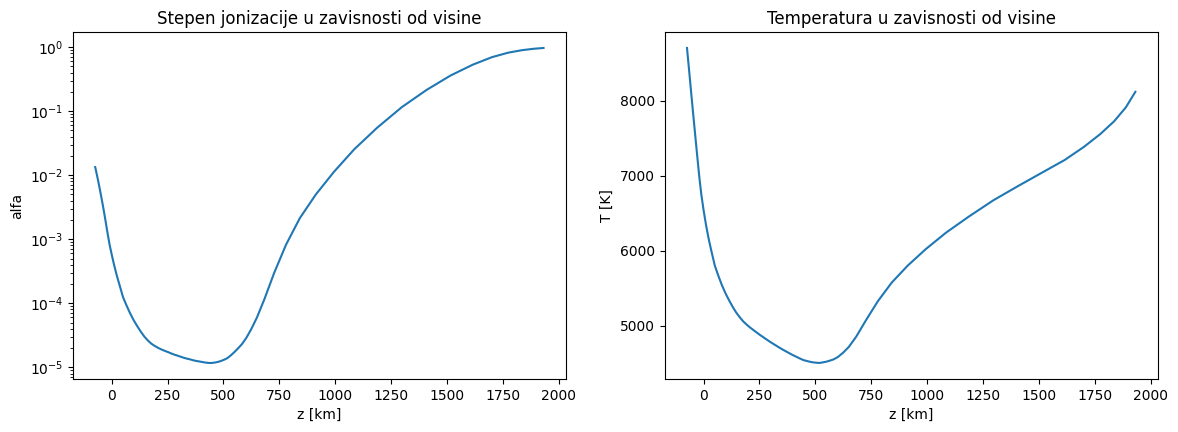

In [34]:
plt.figure(figsize=[14,4.5])
plt.subplot(121)
plt.semilogy(z, alfa)
plt.xlabel("z [km]")
plt.ylabel("alfa")
plt.title("Stepen jonizacije u zavisnosti od visine")
plt.subplot(122)
plt.plot(z, T)
plt.xlabel("z [km]")
plt.ylabel("T [K]")
plt.title("Temperatura u zavisnosti od visine")

### 3) Uporediti koncentraciju elektrona koju smo dobili sa koncentracijom elektrona koji su dati u modelu

In [37]:
ne = pe * 0.1 / k / T

Text(0.5, 1.0, 'Temperatura u zavisnosti od visine')

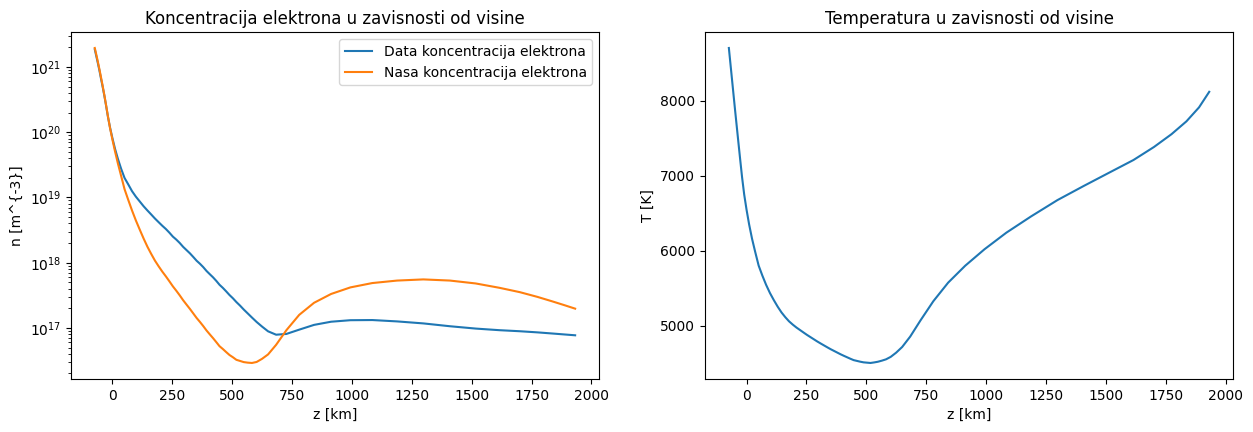

In [39]:
plt.figure(figsize=[15,4.5])
plt.subplot(121)
plt.semilogy(z, ne)
plt.semilogy(z, ne_simple)
plt.legend(["Data koncentracija elektrona", "Nasa koncentracija elektrona"])
plt.xlabel("z [km]")
plt.ylabel("n [m^{-3}]")
plt.title("Koncentracija elektrona u zavisnosti od visine")
plt.subplot(122)
plt.plot(z, T)
plt.xlabel("z [km]")
plt.ylabel("T [K]")
plt.title("Temperatura u zavisnosti od visine")

### Zašto se razlikuju?
### Imamo 3 režima: 

1) Najnižih 100-ak km: svi elektroni dolaze od vodonika (temperatura je relativno visoka), sve je u LTR, imamo dobro poklapanje
2) Od 0 do 700 km: elektroni dolaze uglavnom iz metala, koje mi nemamo (temperatura je relativno niska), sve je u LTR, ali nemamo dobro poklapanje jer smo ignorisali metale
3) Iznad 700 km: elektroni opet dolaze i H, jer je temperatura visoka, ali sada više nemamo LTR, pa je koncentracija elektrona (u ovom slučaju) niža od predvidjene

### Proceniti koncentraciju H-

In [41]:
# Sta cemo da uradimo. pretpostavicemo da elektrona ima koliko smo upravo procenili, pa cemo iskoristiti Sahinu jednacinu za H-
# i dobicemo koncentraciju H- na osnovu H i elektrona.

def nadji_nHminus_simple(nH, ne, T):
    
    gH = 2.0
    gHminus = 1.0
    deltaE = 0.75 * 1.6E-19 # J
        
    return nH * ne / ((2.0 * pi * m_e * k * T / h**2.0) ** 1.5 * 2.0 * gH / gHminus * np.exp(-deltaE/k/T))

In [44]:
nHminus_simple = nadji_nHminus_simple(nH_simple, ne_simple, T)

Text(0, 0.5, 'n [m^{-3}]')

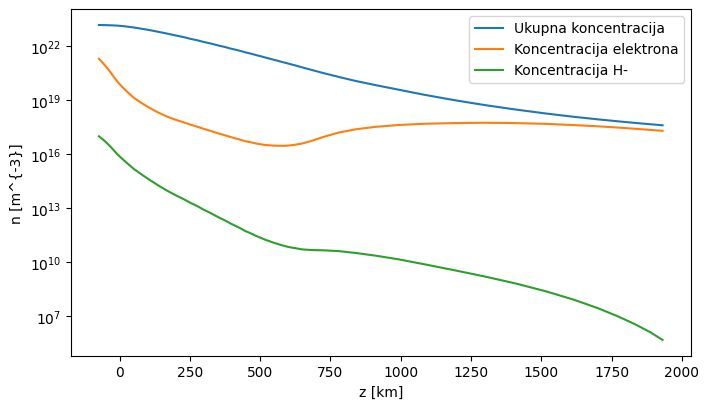

In [45]:
# Hajde da isplotujemo ovaj ne koji smo dobili i ukupan n koji imamo
plt.figure(figsize=[8,4.5])
plt.semilogy(z, n)
plt.semilogy(z, ne_simple)
plt.semilogy(z, nHminus_simple) 
plt.legend(["Ukupna koncentracija", "Koncentracija elektrona", "Koncentracija H-"])
plt.xlabel("z [km]")
plt.ylabel("n [m^{-3}]")

#### Kako je Hminus toliko važan, kada ga ima ovolicno?

Zato što nas zanima apsorpcija u vidljivom delu spektra: od svih atoma neutralnog vodonika samo oni koji su ekscitovani na stanje n = 3 mogu da apsorbuju u vidljivom delu spektra. 

Dakle treba da poredimo Hminus koncentraciju sa koncentracijom vodonika ekscitovanog u n =3 (zvacemo u kodu i = 3, da ne mesamo sa n)

In [50]:
def nadji_ekscitaciju(nH, T):
    gH = 2.0 # Particiona funkcija za vodonik
    gHi = np.array([2.0, 8.0, 18.0])
    eHi = (13.6 - 13.6  / np.array([1.0,2.0,3.0]) ** 2.0)  * 1.6E-19 # J
    print (eHi/1.6E-19) # eV
    nHi = nH[None,:] * gHi[:,None] / gH * np.exp(-eHi[:,None] / k / T[None,:])
    return nHi
    

In [51]:
nHi = nadji_ekscitaciju(nH_simple, T)

[ 0.         10.2        12.08888889]


Text(0, 0.5, 'n [m^{-3}]')

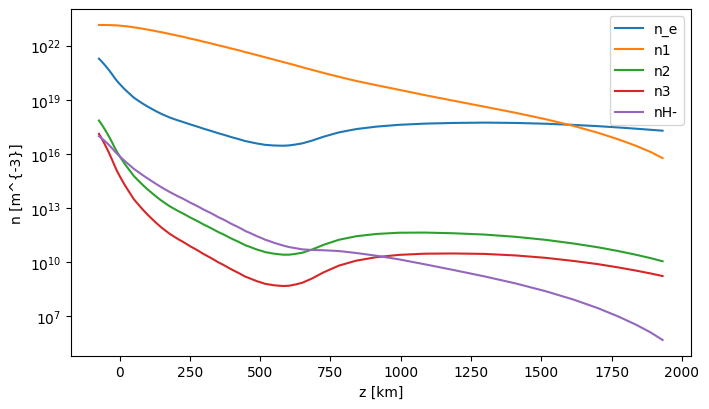

In [52]:
# Hajde sada da uporedimo Hminus sa populacijama vodonika: 
# Hajde da isplotujemo ovaj ne koji smo dobili i ukupan n koji imamo
plt.figure(figsize=[8,4.5])
plt.semilogy(z, ne_simple)
plt.semilogy(z, nHi[0,:])
plt.semilogy(z, nHi[1,:])
plt.semilogy(z, nHi[2,:])
plt.semilogy(z, nHminus_simple)
plt.legend(["n_e", "n1", "n2", "n3", "nH-"])
plt.xlabel("z [km]")
plt.ylabel("n [m^{-3}]")